# Laboratory 1 draft: frequency and damping from a free-vibration record

This notebook is a **starting point**, not a solution. It takes an acceleration record (a phone recording of a system released from an initial displacement) and walks through the steps that are the same at every station:

1. check the record before trusting it,
2. select the free-decay window,
3. estimate the frequency in two independent ways (spectrum and time domain),
4. estimate the damping ratio in two ways (logarithmic decrement and fit to the decay of the peaks),
5. collect the results with their uncertainty.

What it does **not** do: the expected values, the model of your system and the explanation of the discrepancies. Those are yours, and they are what the report is graded on.

Adapt it freely. Your recording is different from your colleagues', so your numbers will be too.

By default it runs on a **synthetic record with a known answer**, so you can check that the pipeline recovers the true values before you point it at real data. Each run generates a slightly different record.

## 1. The data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks, detrend

plt.rcParams['figure.figsize'] = (9, 3.2)

In [2]:
def load_phyphox_csv(filename, time_col=0, acc_col=1, delimiter=',', skiprows=1):
    '''Read a Phyphox export. Returns time (s, starting at 0) and one acceleration column (m/s^2).'''
    data = np.loadtxt(filename, delimiter=delimiter, skiprows=skiprows,
                      usecols=(time_col, acc_col), encoding='utf-8-sig')
    return data[:, 0] - data[0, 0], data[:, 1]


def synthetic_free_decay(f_n=2.30, xi=0.02, amplitude=2.0, t_release=3.0, duration=25.0,
                         fs=200, offset=0.30, drift=0.01, noise=0.03, jitter=0.01, seed=None):
    '''A free decay with the defects of a real phone record: offset, drift, noise, quiet start and
    slightly irregular time stamps. Returns time, acceleration and the true values.'''
    rng = np.random.default_rng(seed)
    n = int(duration * fs)
    t = np.arange(n) / fs + rng.normal(0, jitter / fs, n)
    w_n = 2 * np.pi * f_n
    w_d = w_n * np.sqrt(1 - xi**2)
    tau = np.clip(t - t_release, 0, None)
    a = amplitude * np.exp(-xi * w_n * tau) * np.cos(w_d * tau) * (t >= t_release)
    a += offset + drift * t + rng.normal(0, noise, n)
    return t, a, dict(f_n=f_n, xi=xi)

In [3]:
# Synthetic record with a known answer (f_n = 2.30 Hz, xi = 2 %)
t, a, truth = synthetic_free_decay()

# Your own recording: uncomment, adapt the file name and the columns of your export
# t, a = load_phyphox_csv('my_recording.csv', time_col=0, acc_col=1)
# truth = None

## 2. Check the record before analysing it

Before any calculation, look at the data: how many samples, how regular the sampling is, what the mean is and which axis you are looking at. A recording *with g* has a mean near 9.81 m/s² on the axis that points up or down; *without g* it should be near zero.

samples            : 5000
duration           : 24.99 s
sampling interval  : mean 5.000 ms, std 0.072 ms (1.4% of the mean)
sampling frequency : 200.0 Hz
acceleration       : mean 0.425 m/s2, std 0.380 m/s2


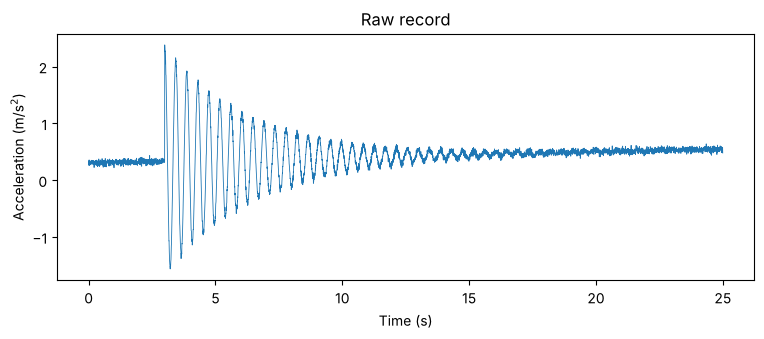

In [4]:
dt = np.diff(t)
print(f'samples            : {len(t)}')
print(f'duration           : {t[-1] - t[0]:.2f} s')
print(f'sampling interval  : mean {dt.mean()*1e3:.3f} ms, std {dt.std()*1e3:.3f} ms ({dt.std()/dt.mean():.1%} of the mean)')
print(f'sampling frequency : {1/dt.mean():.1f} Hz')
print(f'acceleration       : mean {a.mean():.3f} m/s2, std {a.std():.3f} m/s2')

plt.plot(t, a, lw=0.6)
plt.xlabel('Time (s)'); plt.ylabel('Acceleration (m/s$^2$)'); plt.title('Raw record')
plt.show()

The FFT assumes samples at equal intervals. A phone stamps its samples with some jitter, so the record is resampled on a regular grid first. If the irregularity were large (several %), you would have to question the record itself.

In [5]:
def resample_uniform(t, a):
    '''Linear interpolation onto a regular time grid with the median sampling interval.'''
    dt = np.median(np.diff(t))
    t_u = np.arange(t[0], t[-1], dt)
    return t_u, np.interp(t_u, t, a)

t, a = resample_uniform(t, a)
fs = 1 / (t[1] - t[0])

## 3. Select the free-decay window

Keep only the part after the release, and stop where the oscillation sinks into the noise. A longer window gives a finer spectrum (the frequency resolution is $\Delta f = 1/T$, with $T$ the window length), but a window that includes noise only damages the damping estimate.

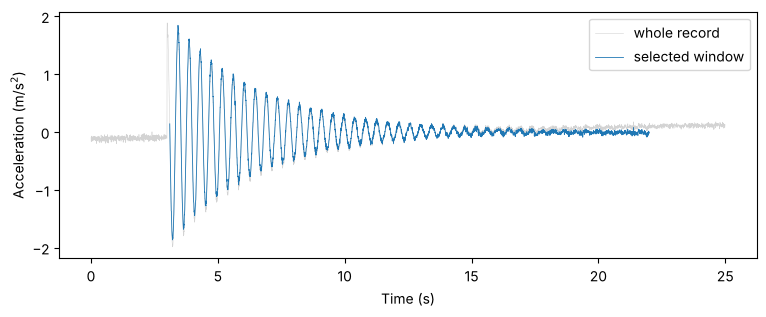

In [6]:
t_start, t_end = 3.1, 22.0      # s, chosen by looking at the plot above

sel = (t >= t_start) & (t <= t_end)
tw = t[sel]
aw = detrend(a[sel])            # removes the offset and the slow drift (linear trend)
T = tw[-1] - tw[0]

plt.plot(t, a - np.mean(a), lw=0.4, color='lightgrey', label='whole record')
plt.plot(tw, aw, lw=0.6, label='selected window')
plt.xlabel('Time (s)'); plt.ylabel('Acceleration (m/s$^2$)'); plt.legend()
plt.show()

## 4. Frequency from the spectrum

The offset and the drift are removed before the transform; otherwise they appear as a large peak at 0 Hz and leak into the neighbouring frequencies. The window (Hann) reduces the leakage caused by cutting the record.

The frequency axis is in **Hz**. Zero-padding makes the curve smoother, and a parabola through the highest point and its two neighbours locates the peak between the frequency bins. Neither improves the resolution: that remains $1/T$.

peak of the spectrum : 2.300 Hz
resolution 1/T       : 0.053 Hz


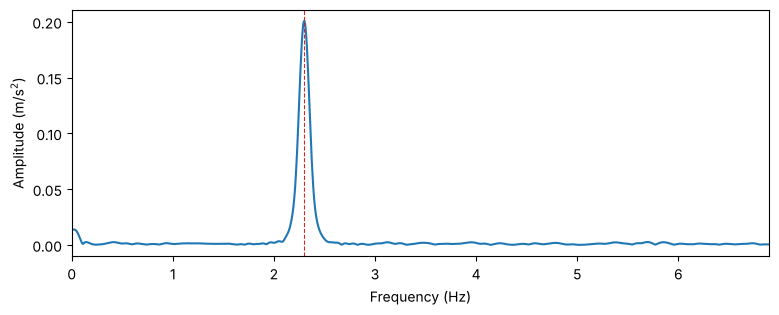

In [7]:
def spectrum(t, a, pad=8, window=True):
    '''One-sided amplitude spectrum in Hz. Offset and drift are removed first.'''
    n = len(a)
    dt = (t[-1] - t[0]) / (n - 1)
    w = np.hanning(n) if window else np.ones(n)
    X = np.fft.rfft(detrend(a) * w, pad * n)
    f = np.fft.rfftfreq(pad * n, dt)
    return f, 2 * np.abs(X) / w.sum()      # a sinusoid of amplitude A shows a peak of height A


def peak_from_spectrum(f, amp, fmin=0.2):
    '''Frequency of the highest peak above fmin (Hz), refined by parabolic interpolation.'''
    k = np.argmax(amp * (f >= fmin))
    y0, y1, y2 = amp[k - 1], amp[k], amp[k + 1]
    return f[k] + 0.5 * (y0 - y2) / (y0 - 2 * y1 + y2) * (f[1] - f[0])


f, amp = spectrum(tw, aw)
f_fft = peak_from_spectrum(f, amp)
df_res = 1 / T

print(f'peak of the spectrum : {f_fft:.3f} Hz')
print(f'resolution 1/T       : {df_res:.3f} Hz')

plt.plot(f, amp)
plt.axvline(f_fft, color='tab:red', lw=0.8, ls='--')
plt.xlim(0, 3 * f_fft)
plt.xlabel('Frequency (Hz)'); plt.ylabel('Amplitude (m/s$^2$)')
plt.show()

## 5. Frequency from the time domain

The period is the time between consecutive peaks. A straight-line fit of the peak times against the cycle number uses all the cycles at once. The cycle number is rounded from the approximate frequency of the spectrum, so that a spurious or a missing peak does not shift the count.

In [8]:
min_amplitude = 0.5             # m/s2, ignore the peaks that are close to the noise level

idx, _ = find_peaks(aw, height=min_amplitude, distance=int(0.7 * fs / f_fft))
tp, ap = tw[idx], aw[idx]
print(f'{len(tp)} peaks used')

cycle = np.round((tp - tp[0]) * f_fft)      # cycle number of each peak, robust to a missing or an extra peak
(T_d, T_0), cov = np.polyfit(cycle, tp, 1, cov=True)
f_d_peaks = 1 / T_d
f_d_peaks_err = np.sqrt(cov[0, 0]) / T_d**2
print(f'frequency from the peaks : {f_d_peaks:.3f} +/- {f_d_peaks_err:.3f} Hz')

12 peaks used
frequency from the peaks : 2.298 +/- 0.003 Hz


## 6. Damping, in two ways

With $\sigma = \xi\omega_n$ the decay rate, the peaks follow $a_k \propto e^{-\sigma t_k}$. What you measure is the damped frequency $\omega_d = \omega_n\sqrt{1-\xi^2}$, which is slightly lower than the natural frequency $\omega_n$. For light damping the difference is negligible (a relative difference of about $\xi^2/2$, 0.02 % for $\xi = 2$ %), so we assume $\omega_d \approx \omega_n \approx \omega = 2\pi f$. Then
$$
\xi = \frac{\sigma}{\omega}
$$

1. **Logarithmic decrement** between the first and the last peak. Quick, but it only uses two peaks.
2. **Straight-line fit** of $\ln a_k$ against $t_k$. Uses all the peaks and gives an uncertainty.

Peaks that stand close to the noise level are biased upward by the noise. That flattens the decay and makes the damping look smaller, and the ± of the straight-line fit (statistical scatter only) does not include it. That is why `min_amplitude` matters.

xi, logarithmic decrement : 0.0184  (1.84%)
xi, fit of the peaks      : 0.0188 +/- 0.0004


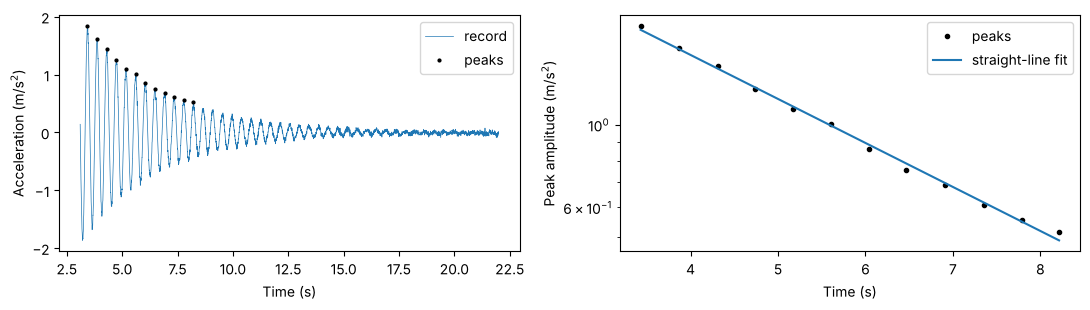

In [9]:
w = 2 * np.pi * f_d_peaks       # damped and natural frequency are assumed to be the same

# (1) logarithmic decrement, xi = delta / (2 pi) for light damping
n_cycles = cycle[-1] - cycle[0]
delta = np.log(ap[0] / ap[-1]) / n_cycles
xi_logdec = delta / (2 * np.pi)

# (2) straight-line fit of ln(peak) against time
(slope, intercept), cov = np.polyfit(tp, np.log(ap), 1, cov=True)
sigma, sigma_err = -slope, np.sqrt(cov[0, 0])
xi_fit = sigma / w
xi_fit_err = sigma_err / w

print(f'xi, logarithmic decrement : {xi_logdec:.4f}  ({xi_logdec:.2%})')
print(f'xi, fit of the peaks      : {xi_fit:.4f} +/- {xi_fit_err:.4f}')

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].plot(tw, aw, lw=0.5, label='record')
ax[0].plot(tp, ap, 'k.', ms=4, label='peaks')
ax[0].set(xlabel='Time (s)', ylabel='Acceleration (m/s$^2$)'); ax[0].legend()
ax[1].semilogy(tp, ap, 'k.', label='peaks')
ax[1].semilogy(tp, np.exp(intercept + slope * tp), label='straight-line fit')
ax[1].set(xlabel='Time (s)', ylabel='Peak amplitude (m/s$^2$)'); ax[1].legend()
plt.tight_layout(); plt.show()

## 7. Results and comparison

The table collects what you measured, with its uncertainty. The frequency you measure is the damped one, $f_d = f_n\sqrt{1-\xi^2}$, slightly below the natural frequency $f_n$. For light damping the difference is negligible and we take them as equal, so the table reports a single frequency and you compare it directly with the expected natural frequency.

The **expected** value is not computed here. Write your own model of the system (masses, stiffness, boundary conditions, the mass of the phone...) and fill in `f_expected`.

In [10]:
rows = [
    ('f [Hz]',   'spectrum',           f_fft,                 df_res),
    ('f [Hz]',   'time domain, peaks', f_d_peaks,             f_d_peaks_err),
    ('xi [-]',   'log. decrement',     xi_logdec,             np.nan),
    ('xi [-]',   'fit of the peaks',   xi_fit,                xi_fit_err),
]
results = pd.DataFrame(rows, columns=['quantity', 'method', 'value', 'uncertainty'])

if truth is not None:       # only for the synthetic record
    results['true value'] = [truth['f_n']]*2 + [truth['xi']]*2

results.round(4)

,quantity,method,value,uncertainty,true value
0,f [Hz],spectrum,2.2997,0.0529,2.30
1,f [Hz],"time domain, peaks",2.2981,0.0033,2.30
2,xi [-],log. decrement,0.0184,NaN,0.02
3,xi [-],fit of the peaks,0.0188,0.0004,0.02


In [11]:
# YOUR expected natural frequency, from your own model of the system
f_expected = ...

if f_expected is not Ellipsis:
    f_measured = f_d_peaks
    print(f'expected {f_expected:.3f} Hz, measured {f_measured:.3f} Hz, '
          f'difference {100 * (f_measured - f_expected) / f_expected:+.1f} %')

## 8. Before you trust a number

- **Resolution.** If the difference between expected and measured frequency is smaller than $\Delta f = 1/T$, the spectrum cannot tell them apart. What can?
- **Window.** Change `t_start`, `t_end` and `min_amplitude` and see how much each estimate moves. That spread is part of your uncertainty.
- **Two estimators that disagree** are telling you something: what do they assume that the other does not? With the synthetic record you can see which one is closer to the truth, and why. Do not assume the same holds for your real record.
- **Axis and orientation.** The phone measures along its own axes. If it is tilted, what do you lose, and in which quantity?
- **The instrument is part of the system.** The phone adds mass and may filter the signal. How much would the frequency change without it? Estimate it instead of asserting it.
- **Amplitude.** Does the damping you identify depend on the amplitude of the oscillation? Compare the first and the last cycles.
- Every discrepancy in your report should come with an estimate of **how much of it** your explanation accounts for.